# Random Forest V2

For V2, I wanted to see how changing the number of trees would affect the Random Forest. I compared 1, 5, 10 and 20 trees using the same samples and other settings as V1.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import platform
import numpy as np
import pandas as pd

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.random_forest import RandomForest

data_dir = project_root.parent / "data"
result_dir = project_root / "results" / "random_forest"
n_trees_values = [1, 5, 10, 20]
v1_summary = pd.read_csv(result_dir / "random_forest_v1_summary.csv", float_precision="round_trip")
print(f"Python {platform.python_version()}, NumPy {np.__version__}, pandas {pd.__version__}")


Python 3.14.3, NumPy 2.4.3, pandas 3.0.1


I started by testing the different tree counts on the image dataset.

In [2]:
X, y, _, _ = load_task("image", data_dir=data_dir)
X_train_full, X_val_full, y_train_full, y_val_full = split_train_val(X, y, val_fraction=0.2, seed=42)
image_X_train = X_train_full[:200]
image_y_train = y_train_full[:200]
image_X_val = X_val_full[:200]
image_y_val = y_val_full[:200]
assert image_X_train.shape == image_X_val.shape == (200, 500)
v1_validation = pd.read_csv(result_dir / "random_forest_v1_image_validation.csv")
v1_result = v1_summary.loc[v1_summary.dataset == "image"].iloc[0]
assert v1_validation.validation_index.tolist() == list(range(200))
assert v1_validation.actual_label.tolist() == image_y_val.tolist()
assert v1_result.n_trees == 5 and v1_result.max_depth == 2
assert v1_result.min_samples == 1 and v1_result.n_features == "sqrt"
assert v1_result.criterion == "entropy" and not v1_result.normalized

image_rows = []
image_validation_predictions = {}
for n_trees in n_trees_values:
    clf = RandomForest(n_trees=n_trees, max_depth=2, min_samples=1, n_features="sqrt", seed=42)
    start = perf_counter()
    assert clf.fit(image_X_train, image_y_train) is clf
    fit_time = perf_counter() - start
    training_accuracy = clf.score(image_X_train, image_y_train)
    start = perf_counter()
    predictions = clf.predict(image_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(predictions, image_y_val)) / 200
    oob_accuracy = clf.oob_score(image_y_train)
    oob_covered = sum(bool(v) for v in clf._oob_preds.values())
    assert len(clf.trees) == n_trees and len(predictions) == 200
    assert all(t.criterion == "entropy" and t.n_features == 22 for t in clf.trees)
    assert all(0 <= p <= 49 for p in predictions)
    if n_trees == 5:
        assert predictions == v1_validation.predicted_label.tolist()
        assert training_accuracy == v1_result.training_accuracy
        assert validation_accuracy == v1_result.validation_accuracy
        assert oob_accuracy == v1_result.oob_accuracy
        print("Five trees reproduce all V1 predictions and train/validation/OOB accuracies exactly.")
    image_validation_predictions[n_trees] = predictions
    image_rows.append({
        "dataset": "image", "version": "V2", "n_trees": n_trees,
        "max_depth": 2, "min_samples": 1, "n_features": "sqrt",
        "criterion": "entropy", "normalized": False,
        "training_samples": 200, "validation_samples": 200,
        "training_accuracy": training_accuracy, "validation_accuracy": validation_accuracy,
        "oob_accuracy": oob_accuracy, "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"image: {n_trees} trees, training={training_accuracy:.2%}, validation={validation_accuracy:.2%}, OOB={oob_accuracy:.6%} ({oob_covered}/200)")
    print(f"Fit={fit_time:.9f} s, validation prediction={prediction_time:.9f} s")
image_summary = pd.DataFrame(image_rows)


image: 1 trees, training=8.00%, validation=2.00%, OOB=2.702703% (74/200)
Fit=0.023602500 s, validation prediction=0.000187583 s
Five trees reproduce all V1 predictions and train/validation/OOB accuracies exactly.
image: 5 trees, training=9.00%, validation=2.50%, OOB=2.247191% (178/200)
Fit=0.118539667 s, validation prediction=0.000388084 s
image: 10 trees, training=9.00%, validation=3.00%, OOB=1.522843% (197/200)
Fit=0.237604875 s, validation prediction=0.000656167 s
image: 20 trees, training=11.50%, validation=3.50%, OOB=1.000000% (200/200)
Fit=0.471635583 s, validation prediction=0.001157542 s


Then I repeated the same experiment with the sentiment dataset.

In [3]:
X, y, _, _ = load_task("sentiment", data_dir=data_dir)
X_train_full, X_val_full, y_train_full, y_val_full = split_train_val(X, y, val_fraction=0.2, seed=42)
sentiment_X_train = X_train_full[:200]
sentiment_y_train = y_train_full[:200]
sentiment_X_val = X_val_full[:200]
sentiment_y_val = y_val_full[:200]
assert sentiment_X_train.shape == sentiment_X_val.shape == (200, 768)
v1_validation = pd.read_csv(result_dir / "random_forest_v1_sentiment_validation.csv")
v1_result = v1_summary.loc[v1_summary.dataset == "sentiment"].iloc[0]
assert v1_validation.validation_index.tolist() == list(range(200))
assert v1_validation.actual_label.tolist() == sentiment_y_val.tolist()
assert v1_result.n_trees == 5 and v1_result.max_depth == 3
assert v1_result.min_samples == 1 and v1_result.n_features == "sqrt"
assert v1_result.criterion == "entropy" and not v1_result.normalized

sentiment_rows = []
sentiment_validation_predictions = {}
for n_trees in n_trees_values:
    clf = RandomForest(n_trees=n_trees, max_depth=3, min_samples=1, n_features="sqrt", seed=42)
    start = perf_counter()
    assert clf.fit(sentiment_X_train, sentiment_y_train) is clf
    fit_time = perf_counter() - start
    training_accuracy = clf.score(sentiment_X_train, sentiment_y_train)
    start = perf_counter()
    predictions = clf.predict(sentiment_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(predictions, sentiment_y_val)) / 200
    oob_accuracy = clf.oob_score(sentiment_y_train)
    oob_covered = sum(bool(v) for v in clf._oob_preds.values())
    assert len(clf.trees) == n_trees and len(predictions) == 200
    assert all(t.criterion == "entropy" and t.n_features == 27 for t in clf.trees)
    assert all(0 <= p <= 2 for p in predictions)
    if n_trees == 5:
        assert predictions == v1_validation.predicted_label.tolist()
        assert training_accuracy == v1_result.training_accuracy
        assert validation_accuracy == v1_result.validation_accuracy
        assert oob_accuracy == v1_result.oob_accuracy
        print("Five trees reproduce all V1 predictions and train/validation/OOB accuracies exactly.")
    sentiment_validation_predictions[n_trees] = predictions
    sentiment_rows.append({
        "dataset": "sentiment", "version": "V2", "n_trees": n_trees,
        "max_depth": 3, "min_samples": 1, "n_features": "sqrt",
        "criterion": "entropy", "normalized": False,
        "training_samples": 200, "validation_samples": 200,
        "training_accuracy": training_accuracy, "validation_accuracy": validation_accuracy,
        "oob_accuracy": oob_accuracy, "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"sentiment: {n_trees} trees, training={training_accuracy:.2%}, validation={validation_accuracy:.2%}, OOB={oob_accuracy:.6%} ({oob_covered}/200)")
    print(f"Fit={fit_time:.9f} s, validation prediction={prediction_time:.9f} s")
sentiment_summary = pd.DataFrame(sentiment_rows)


sentiment: 1 trees, training=59.50%, validation=40.50%, OOB=45.945946% (74/200)
Fit=0.185849125 s, validation prediction=0.000228416 s
Five trees reproduce all V1 predictions and train/validation/OOB accuracies exactly.
sentiment: 5 trees, training=69.50%, validation=38.50%, OOB=43.820225% (178/200)
Fit=0.899740708 s, validation prediction=0.000497833 s
sentiment: 10 trees, training=73.50%, validation=40.00%, OOB=41.116751% (197/200)
Fit=1.790317334 s, validation prediction=0.000801375 s
sentiment: 20 trees, training=80.50%, validation=41.00%, OOB=46.500000% (200/200)
Fit=3.591215167 s, validation prediction=0.001512542 s


Finally, I selected the best tree count for each dataset using validation accuracy and saved its predictions. If accuracies tie, I keep fewer trees.

In [4]:
summary = pd.DataFrame(image_rows + sentiment_rows)
assert len(summary) == 8
summary.to_csv(result_dir / "random_forest_v2_summary.csv", index=False)
selected = {}
for task, rows, actual, prediction_map in [
    ("image", image_rows, image_y_val, image_validation_predictions),
    ("sentiment", sentiment_rows, sentiment_y_val, sentiment_validation_predictions),
]:
    best = rows[0]
    for row in rows[1:]:
        if row["validation_accuracy"] > best["validation_accuracy"]:
            best = row
    selected[task] = best
    path = result_dir / f"random_forest_v2_{task}_validation.csv"
    pd.DataFrame({"validation_index": range(200), "actual_label": actual,
                  "predicted_label": prediction_map[best["n_trees"]]}).to_csv(path, index=False)
    saved = pd.read_csv(path)
    assert saved.shape == (200, 3) and not saved.isna().any().any()
    assert saved.validation_index.tolist() == list(range(200))
    assert saved.actual_label.tolist() == actual.tolist()
    assert saved.predicted_label.tolist() == prediction_map[best["n_trees"]]
    assert sum(saved.actual_label == saved.predicted_label) / 200 == best["validation_accuracy"]
    print(f"{task}: selected {best['n_trees']} trees, validation={best['validation_accuracy']:.2%}")
print(summary.to_string(index=False))

tracker_path = result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker.version.is_unique
v1_before = tracker.loc[tracker.version == "V1"].copy()
v2_row = {
    "version": "V2", "image_validation_accuracy": selected["image"]["validation_accuracy"],
    "sentiment_validation_accuracy": selected["sentiment"]["validation_accuracy"],
    "kaggle_public_score": "", "submitted_to_kaggle": False, "submission_filename": "",
    "notes": f"Tested 1,5,10,20 trees; selected image={selected['image']['n_trees']}, sentiment={selected['sentiment']['n_trees']}; depth=2/3; sqrt; min_samples=1; entropy; seed=42; original features; 200 train/200 validation per task. No Kaggle candidate.",
}
matching = tracker.version == "V2"
if matching.any():
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "notes"):
        tracker.loc[matching, column] = v2_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v2_row])], ignore_index=True)
assert tracker.version.is_unique
assert tracker.loc[tracker.version == "V1"].to_dict("records") == v1_before.to_dict("records")
tracker.to_csv(tracker_path, index=False)


image: selected 20 trees, validation=3.50%
sentiment: selected 20 trees, validation=41.00%
  dataset version  n_trees  max_depth  min_samples n_features criterion  normalized  training_samples  validation_samples  training_accuracy  validation_accuracy  oob_accuracy  fit_time_seconds  prediction_time_seconds
    image      V2        1          2            1       sqrt   entropy       False               200                 200              0.080                0.020      0.027027          0.023603                 0.000188
    image      V2        5          2            1       sqrt   entropy       False               200                 200              0.090                0.025      0.022472          0.118540                 0.000388
    image      V2       10          2            1       sqrt   entropy       False               200                 200              0.090                0.030      0.015228          0.237605                 0.000656
    image      V2       20       

I plotted training and validation accuracy to compare the different numbers of trees.

Matplotlib 3.11.2; graphs rendered from the saved V2 trial values.


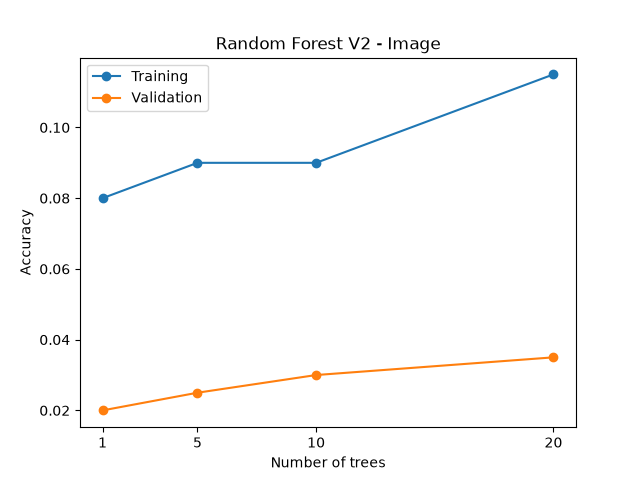

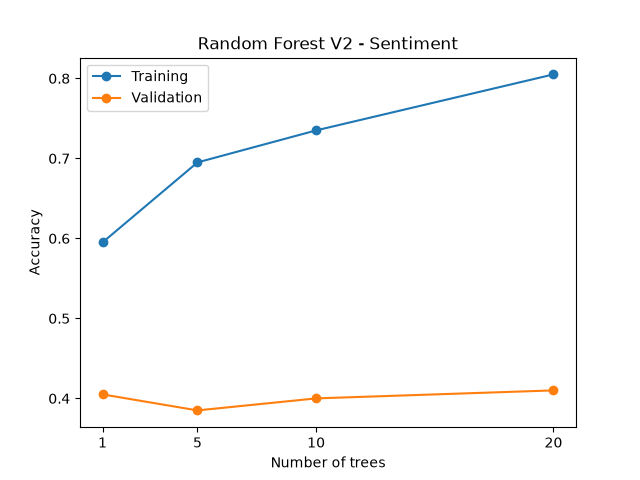

In [5]:
import matplotlib.pyplot as plt

for task, task_summary in [("image", image_summary), ("sentiment", sentiment_summary)]:
    plt.figure()
    plt.plot(task_summary["n_trees"], task_summary["training_accuracy"], marker="o", label="Training")
    plt.plot(task_summary["n_trees"], task_summary["validation_accuracy"], marker="o", label="Validation")
    plt.xlabel("Number of trees")
    plt.ylabel("Accuracy")
    plt.title(f"Random Forest V2 - {task.capitalize()}")
    plt.xticks(n_trees_values)
    plt.legend()
    plt.savefig(result_dir / f"random_forest_v2_{task}_n_trees.png")
    plt.show()


I selected 20 trees for image (3.50% validation accuracy) and 20 trees for sentiment (41.00%). The five-tree models reproduced V1 exactly. These results use only 200 validation examples per dataset.